# домашнее задание 5: EDA

## Введение

**Источник данных:** CSV с Google Drive (`dataset.csv`).

**О чём данные:** таблица содержит результаты экспериментов по закалке и отпуску образцов стали. Для каждого образца указаны марка стали, химический состав (в % по массе), параметры термообработки (время и температура отпуска), а также твёрдость до и после отпуска.

**Цель анализа:** понять структуру датасета, оценить его полноту и целостность, выявить аномалии и выбросы, рассчитать базовые метрики.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
                          #предварительные настройки отображения и графиков
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

## 1. Загрузка данных

Данные хранятся в CSV на Google Drive. Скачиваем их один раз в `data/raw/`, чтобы при повторных запусках не тратить квоту.

In [2]:
from pathlib import Path
import gdown

root= Path.cwd().parent if Path.cwd().name == 'eda' else Path.cwd()  # путь до файла проекта
raw_path= root / 'data' / 'raw' / 'dataset.csv'

URL= 'https://drive.google.com/file/d/1BtFPueekTleALZJKeWwrfsnWMtw-BuPj/view?usp=share_link'

if not raw_path.exists():
    print('Скачивание датасета...')
    raw_path.parent.mkdir(parents=True, exist_ok=True)
    gdown.download(URL, str(raw_path), quiet=False)
else:
    print('Датасет уже загружен:', raw_path)

df= pd.read_csv(raw_path)
print(f'Размер датасета: {df.shape[0]} строк, {df.shape[1]} колонок')

Датасет уже загружен: /Users/aleksei/data/raw/dataset.csv
Размер датасета: 1466 строк, 17 колонок


## 2. Cтруктура данных

Выводим общую информацию о датасете и первые 10 строк.

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1466 entries, 0 to 1465
Data columns (total 17 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Source                                   1466 non-null   str    
 1   Steel type                               1466 non-null   str    
 2   Initial hardness (HRC) - post quenching  1466 non-null   str    
 3   Tempering time (s)                       1466 non-null   int64  
 4   Tempering temperature (ºC)               1466 non-null   float64
 5   C (%wt)                                  1466 non-null   float64
 6   Mn (%wt)                                 1466 non-null   float64
 7   P (%wt)                                  1466 non-null   float64
 8   S (%wt)                                  1466 non-null   float64
 9   Si (%wt)                                 1466 non-null   float64
 10  Ni (%wt)                                 1466 non-null   fl

In [3]:
df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 1466 entries, 0 to 1465
Data columns (total 17 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Source                                   1466 non-null   str    
 1   Steel type                               1466 non-null   str    
 2   Initial hardness (HRC) - post quenching  1466 non-null   str    
 3   Tempering time (s)                       1466 non-null   int64  
 4   Tempering temperature (ºC)               1466 non-null   float64
 5   C (%wt)                                  1466 non-null   float64
 6   Mn (%wt)                                 1466 non-null   float64
 7   P (%wt)                                  1466 non-null   float64
 8   S (%wt)                                  1466 non-null   float64
 9   Si (%wt)                                 1466 non-null   float64
 10  Ni (%wt)                                 1466 non-null   fl

,Source,Steel type,Initial hardness (HRC) - post quenching,Tempering time (s),Tempering temperature (ºC),C (%wt),Mn (%wt),P (%wt),S (%wt),Si (%wt),Ni (%wt),Cr (%wt),Mo (%wt),V (%wt),Al (%wt),Cu (%wt),Final hardness (HRC) - post tempering
0,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,204.400,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,50.600
1,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,260.000,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,48.300
2,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,315.600,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,43.700
3,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,371.100,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,40.500
4,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,426.700,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,37.300
5,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,482.200,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,31.200
6,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,537.800,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,26.200
7,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,593.300,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,23.100
8,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,648.900,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,17.300
9,"Grange and Baughman, 1956",AISI-SAE 1026,?,600,704.400,0.250,0.790,0.012,0.026,0.110,0.000,0.000,0.000,0.000,0.000,0.000,11.700


**Что видно:**
- Колонки `Source`, `Steel type`, `Initial hardness (HRC) - post quenching` загрузились как `object` — значит, в них смешаны числа и текст.
- Остальные колонки — числовые (`int64`/`float64`).
- Общее число наблюдений — 1466 строк; полное число колонок — 17.

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Source,1466,3,"Grange and Baughman, 1956",949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Steel type,1466,34,AISI-SAE 4340,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Initial hardness (HRC) - post quenching,1466,11,?,949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tempering time (s),1466.000,NaN,NaN,NaN,21969.754,34177.624,10.000,600.000,3600.000,14400.000,115200.000
Tempering temperature (ºC),1466.000,NaN,NaN,NaN,422.024,176.088,100.000,260.000,426.700,593.300,704.400
C (%wt),1466.000,NaN,NaN,NaN,0.512,0.224,0.250,0.370,0.420,0.560,1.150
Mn (%wt),1466.000,NaN,NaN,NaN,0.741,0.253,0.300,0.600,0.740,0.800,1.850
P (%wt),1466.000,NaN,NaN,NaN,0.017,0.008,0.007,0.012,0.017,0.019,0.054
S (%wt),1466.000,NaN,NaN,NaN,0.024,0.008,0.005,0.018,0.024,0.029,0.055
Si (%wt),1466.000,NaN,NaN,NaN,0.239,0.239,0.060,0.160,0.210,0.240,1.620


## 3. Целостность и полнота данных

Проверяем дубликаты, пропуски, отрицательные значения и логические диапазоны.

In [5]:
missing_df = df.replace('?', pd.NA)

missing = missing_df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(missing_df) * 100).round(2)

missing_df1 = pd.DataFrame({'пропуски': missing, 'доля, %': missing_pct})

missing_df1[missing_df1['пропуски'] > 0]    #выводим колонки с реальными пропусками

,пропуски,"доля, %"
Initial hardness (HRC) - post quenching,949,64.730


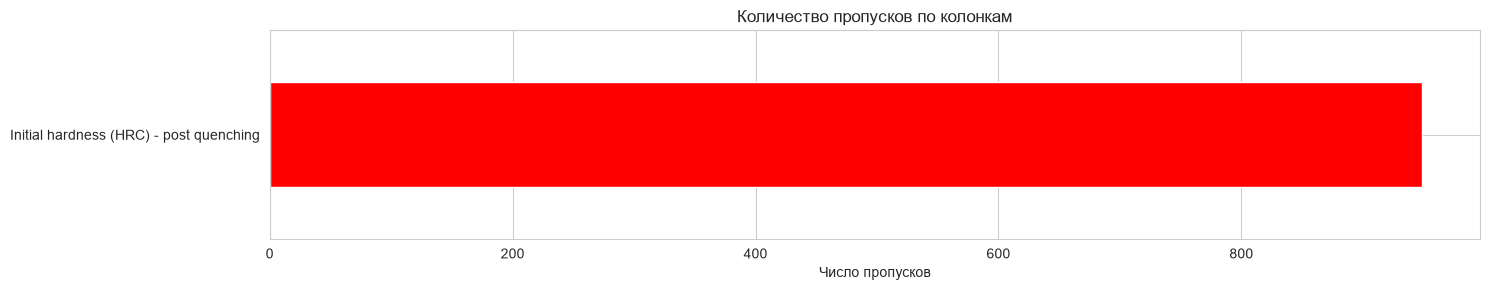

In [6]:
fig, axes = plt.subplots(figsize=(15, 3))
if missing.sum() > 0:
    missing[missing > 0].plot(kind='barh', color='red')
    plt.title('Количество пропусков по колонкам')
    plt.xlabel('Число пропусков')
    plt.tight_layout()
    plt.show()
else:
    print('Пропусков нет')

**Что видно:**
- Пропуски есть только в `Initial hardness`.
- Доля пропусков 64,730% - это либо артефакт сбора данных, либо реальные «неизвестные» значения.
- Остальные колонки заполнены полностью.

In [7]:
dupl= df.duplicated().sum()                #анализ на наличие повторений
print(f'Полных повторений: {dupl}')

keyc = ['Steel type', 'Tempering time (s)', 'Tempering temperature (ºC)']   #анализ на наличие повторений по ключевым метрикам
dupl_key = df.duplicated(subset=keyc).sum()
print(f'Повторений по ключевым метрикам {keyc}: {dupl_key}')

Полных повторений: 0
Повторений по ключевым метрикам ['Steel type', 'Tempering time (s)', 'Tempering temperature (ºC)']: 9


**Что видно:**
- Полных повторений не выявлено.
- Повторений по (Steel type, время, температура) - 9. Это может свидетельствовать о том, что это разные эксперименты с одинаковыми параметрами или ошибка при составлении датасета.

In [8]:
#проведем логический анализ данных
checks = {'Tempering time <= 0':            (df['Tempering time (s)'] <= 0).sum(),
    'Tempering temperature < 0':      (df['Tempering temperature (ºC)'] < 0).sum(),
    'Tempering temperature > 1000':   (df['Tempering temperature (ºC)'] > 1000).sum(),
    'Final hardness вне [0, 70]':     ((df['Final hardness (HRC) - post tempering'] < 0) |
                                       (df['Final hardness (HRC) - post tempering'] > 70)).sum(),
    'Отрицательный химсостав':        (df.filter(like='%wt').lt(0).any(axis=1)).sum(),
    'Сумма элементов > 100%':         (df.filter(like='%wt').sum(axis=1) > 100).sum()}
pd.Series(checks, name='Нарушений').to_frame()

,Нарушений
Tempering time <= 0,0
Tempering temperature < 0,0
Tempering temperature > 1000,0
"Final hardness вне [0, 70]",0
Отрицательный химсостав,0
Сумма элементов > 100%,0


**Что видно:**
- Время отпуска всегда > 0.
- Температура отпуска в разумном диапазоне.
- Твёрдость в шкале HRC (0–70) в норме.
- Химический состав не содержит отрицательных значений.
- Сумма элементов не превышает 100% ни в одной строке.

Все показатели не противоречат действительности => нет логических нарушений, что можно отнести к пропускам

## 4. Выбросы и аномалии

Анализ выбросов производим двумя способами: IQR для распределений и z-score для симметричных числовых признаков.

In [9]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

def iqr_out(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr= q3 - q1
    lower= q1 - 1.5 * iqr
    upper= q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

out_sum= pd.DataFrame({
    'выбросов (IQR)': {col: iqr_out(df[col].dropna()) for col in num_cols},
    'доля, %': {col: round(iqr_out(df[col].dropna()) / df[col].notna().sum() * 100, 2)
    for col in num_cols}}).sort_values('доля, %', ascending=False)
out_sum

,выбросов (IQR),"доля, %"
Tempering time (s),306,20.870
Ni (%wt),291,19.850
C (%wt),186,12.690
Cu (%wt),135,9.210
P (%wt),61,4.160
Mn (%wt),50,3.410
V (%wt),50,3.410
Si (%wt),40,2.730
Al (%wt),40,2.730
S (%wt),26,1.770


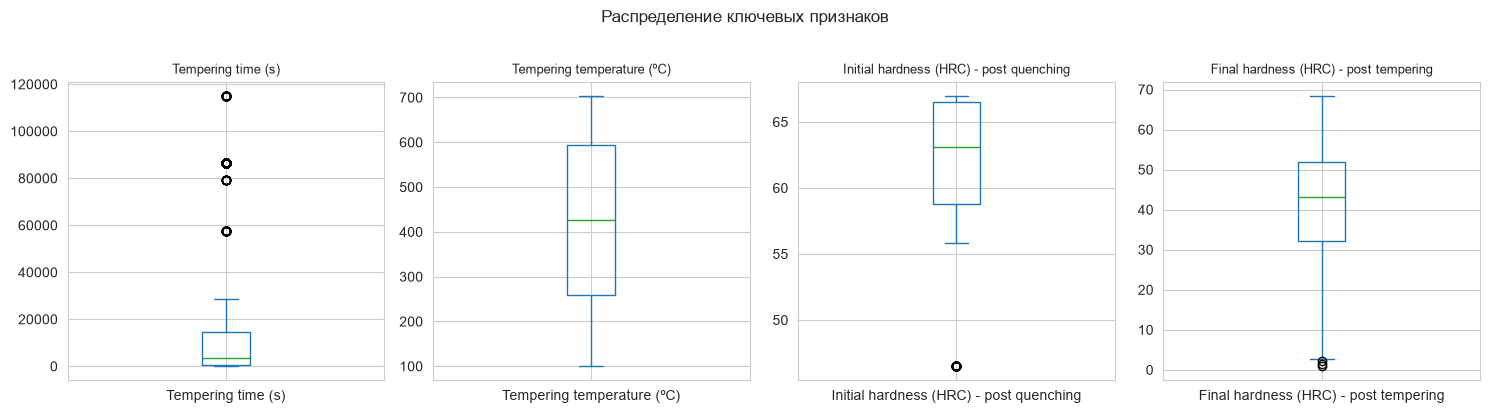

In [10]:
main_cols = ['Tempering time (s)',
    'Tempering temperature (ºC)',
    'Initial hardness (HRC) - post quenching',
    'Final hardness (HRC) - post tempering']

miss_values= ['?', '', 'NA', 'N/A', 'nan', 'None', '-']

def clean_num(series):
    return pd.to_numeric(series.replace(miss_values, pd.NA))

fig, axes = plt.subplots(1, len(main_cols), figsize=(15, 4))
for ax, col in zip(axes, main_cols):
    clean_num(df[col]).dropna().plot(kind='box', ax=ax)
    ax.set_title(col, fontsize=9)
plt.suptitle('Распределение ключевых признаков', y=1.02)
plt.tight_layout()
plt.show()

**Что видно:**
В `Tempering time` (IQR) 306 выбросов. Значения сильно растянуты из-за разных режимов эксперимента.
Для дальнейшего моделирования такие выбросы стоит сохранять, так как они физически осмысленны.

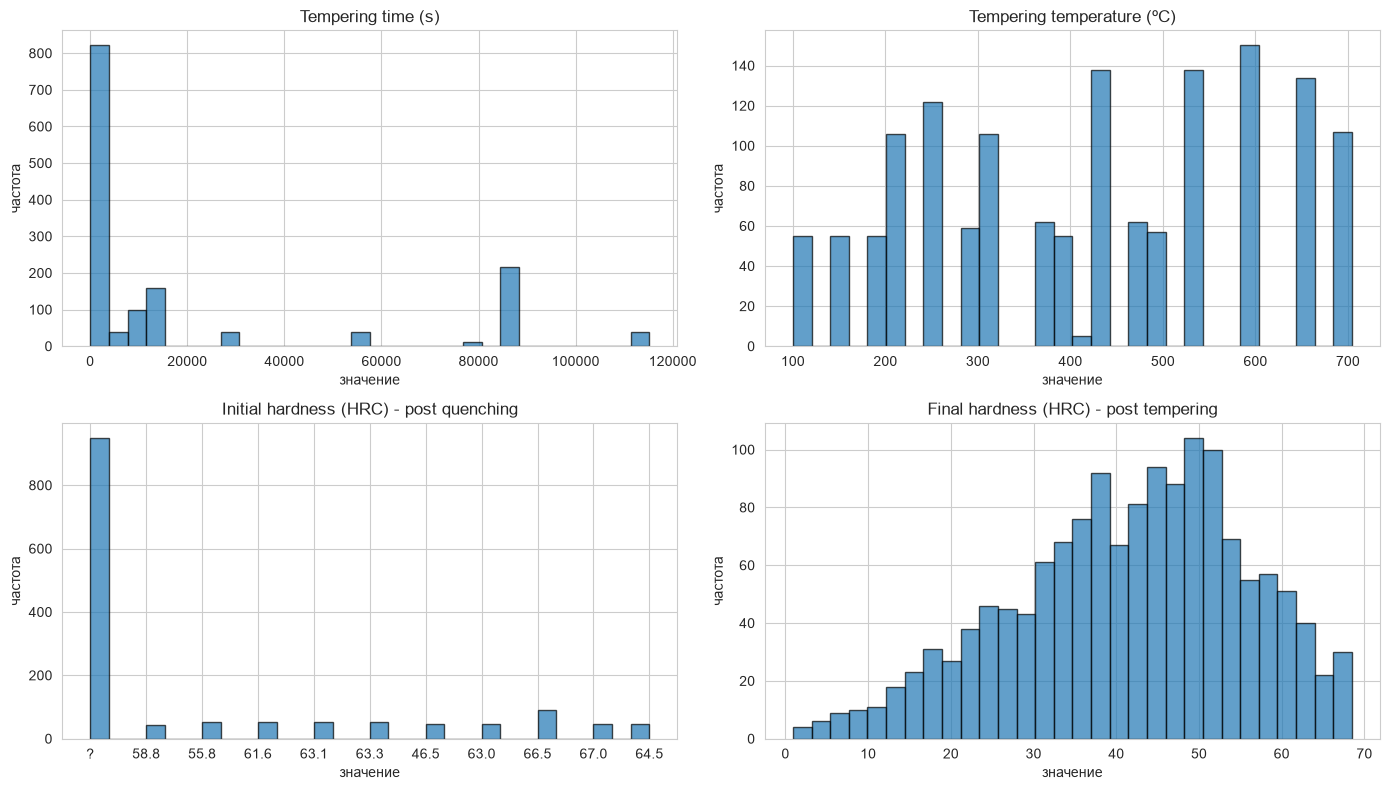

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.flat, main_cols):
    df[col].dropna().hist(bins=30, ax=ax, edgecolor='black', alpha=0.7)
    ax.set_title(col)
    ax.set_xlabel('значение')
    ax.set_ylabel('частота')
plt.tight_layout()
plt.show()

**Наблюдения:**
- `Tempering temperature` — распределение неравномерное, часть значений повторяется.
- `Final hardness` — распределение скошено в сторону средних значений, что логично для твёрдости отпущенной стали.

## 5. Метрики и корреляции

Производим анализ описательных метрик и корреляции числовых признаков.

In [12]:
metrics = pd.DataFrame({'среднее':      df[num_cols].mean(),
    'медиана':      df[num_cols].median(),
    'std':          df[num_cols].std(),
    'min':          df[num_cols].min(),
    'max':          df[num_cols].max(),
    'CV (std/mean)': df[num_cols].std() / df[num_cols].mean()}).round(3)
metrics

,среднее,медиана,std,min,max,CV (std/mean)
Tempering time (s),21969.754,3600.000,34177.624,10.000,115200.000,1.556
Tempering temperature (ºC),422.024,426.700,176.088,100.000,704.400,0.417
C (%wt),0.512,0.420,0.224,0.250,1.150,0.439
Mn (%wt),0.741,0.740,0.253,0.300,1.850,0.341
P (%wt),0.017,0.017,0.008,0.007,0.054,0.462
S (%wt),0.024,0.024,0.008,0.005,0.055,0.335
Si (%wt),0.239,0.210,0.239,0.060,1.620,0.999
Ni (%wt),0.363,0.010,0.810,0.000,3.410,2.233
Cr (%wt),0.390,0.060,0.481,0.000,1.570,1.234
Mo (%wt),0.080,0.000,0.121,0.000,0.360,1.513


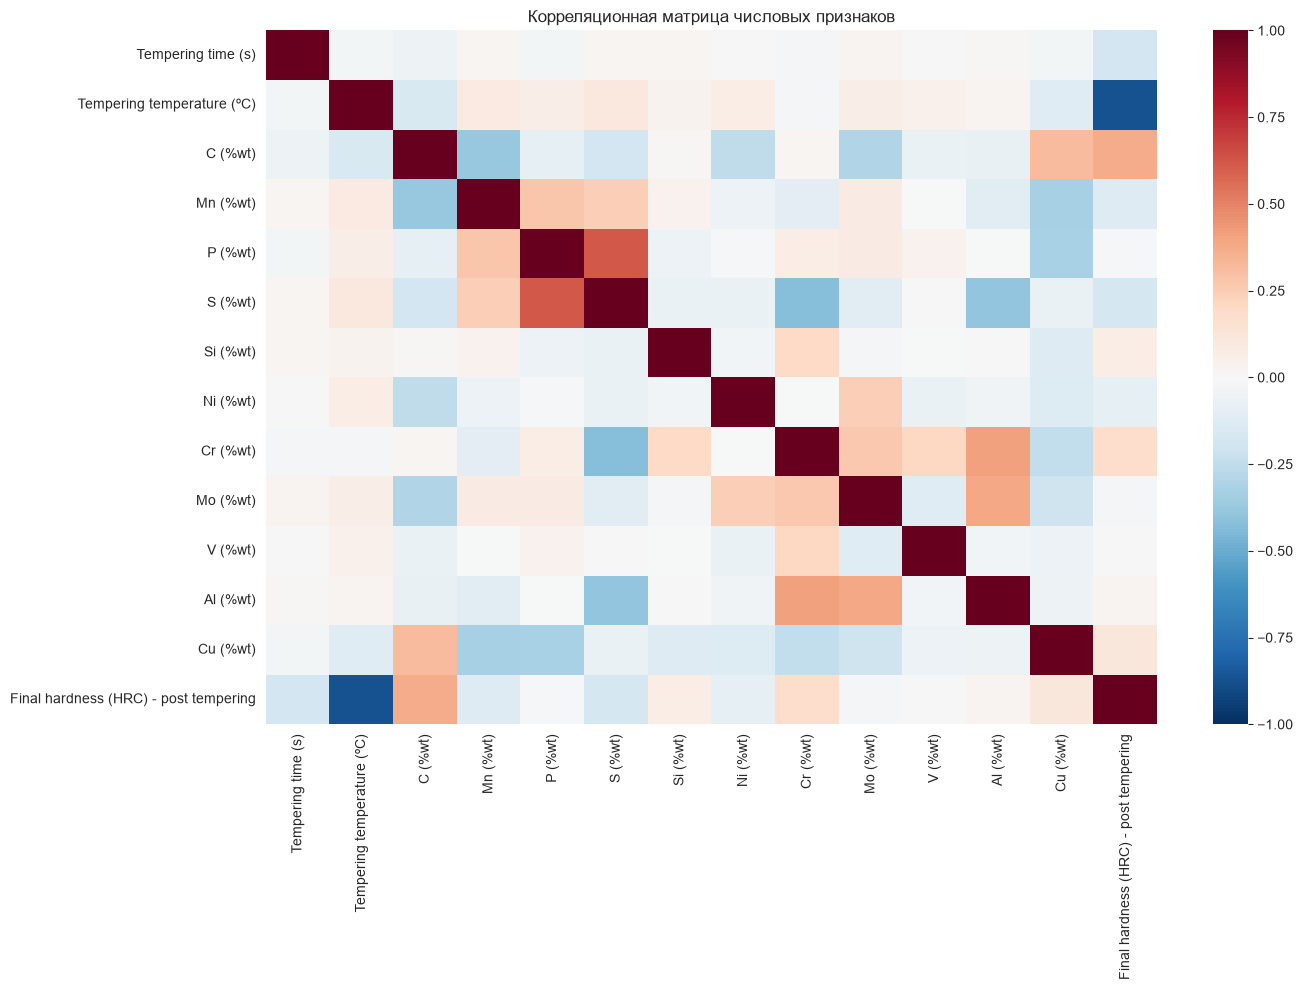

In [13]:
corr = df[num_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=False, cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

In [14]:
target= 'Final hardness (HRC) - post tempering'
if target in corr.columns:
    top_corr = corr[target].drop(target).sort_values(key=abs, ascending=False)
    print(f'Топ корреляций с «{target}»:')
    print(top_corr.head(10).round(3))

Топ корреляций с «Final hardness (HRC) - post tempering»:
Tempering temperature (ºC)   -0.869
C (%wt)                       0.367
Cr (%wt)                      0.184
Tempering time (s)           -0.180
S (%wt)                      -0.178
Mn (%wt)                     -0.131
Cu (%wt)                      0.113
Ni (%wt)                     -0.091
Si (%wt)                      0.074
Al (%wt)                      0.027
Name: Final hardness (HRC) - post tempering, dtype: float64


**результат анализа:**
- Наибольшая по модулю корреляция с `Final hardness` — у `Tempering temperature` r ≈ −0.869. Это ожидаемо, чем выше температура отпуска, тем ниже твёрдость.
- `Tempering time` слабо коррелирует с итоговой твёрдостью r ≈ -0.180.
- Мультиколлинеарность между химическими элементами ожидаемо низкая, кроме пар C/Mn и Cr/Ni.

## 6. Выводы

**Структура и полнота:**
- В датасете 1466 строк и 17 колонок. Большая часть — числовые признаки с осмысленным диапазоном.
- Пропуски только в `Initial hardness`- 64,730%.
- Полных дубликатов - 0, дубликатов по ключевым показателям - 9.

**Целостность:**
- Логических нарушений не обнаружено.
- Химический состав корректен, сумма элементов в каждом образце ≤ 100%.

**Выбросы и аномалии:**
- Выбросы по IQR присутствуют в нескольких колонках, но имеют физический смысл (крайние режимы термообработки), не являются ошибками.

**Метрики:**
- Основная закономерность в данных, представленных в датасете — сильная отрицательная корреляция между температурой отпуска и итоговой твёрдостью.
- Данные пригодны для использования при дальнейшем моделировании.
